# PTM3D Tutorial 02 — Europa surface thermal, with a Jupiter eclipse

A self-contained walkthrough of PTM3D's Europa quickstart: one full Europa
"day" (one orbit around Jupiter, 3.55 Earth days — Europa is tidally locked,
so the orbit period *is* the diurnal period) of surface temperature over the
entire moon on a coarse global mesh. It follows the same structure and reader
code as [`01_moon_diurnal.ipynb`](01_moon_diurnal.ipynb) and the lunar
tutorial [`02_lunar_diurnal_icosphere.md`](../02_lunar_diurnal_icosphere.md).

## What you'll learn

- The Europa-specific config blocks: `body: Europa` (built-in ephemeris +
  ice-regolith thermal defaults), Jupiter as the **primary body** (reflected
  light *and* thermal IR — two physically distinct, separately-gated terms),
  and why `duration_days: 3.55` is Europa's whole diurnal cycle.
- How to run `ptm_thermal_sim` from Python and stream its progress.
- The on-disk output format (`statistics/*.bin`, per-timestep snapshots,
  `mesh.ply` with per-face lat/lon), read with the Python standard library
  and NumPy.
- The **Jupiter eclipse**: once per orbit, Europa passes through Jupiter's
  shadow and direct solar flux drops to exactly zero, body-wide, for ~2.7
  hours. This run's `start_time` is chosen so the output window captures one.
- Why Europa's night side stays much *warmer relative to its day side* than
  the Moon's does, despite broadly comparable regolith thermal inertia.

**Cost:** CPU-only, ~10-15 s on a many-core workstation (measured below),
under a minute on a modest laptop, <1 GB RAM. The mesh is a 5120-face
icosphere with radiation exchange off (a convex sphere has no self-view), so
no GPU and no view-factor matrix are involved.

**Prerequisite:** a built `ptm_thermal_sim` binary and the Europa SPICE
kernels, which (unlike the Moon's) include the 1.1 GB Galilean-satellite
ephemeris `jup365.bsp` — Europa's position *relative to Jupiter* is what
produces the eclipse. The next cell checks for both and prints the command to
run if either is missing.


## 0. Environment check

Checks, in order: Python version, `numpy` and `matplotlib`, the
`ptm_thermal_sim` binary, and — Europa-specific — **both** SPICE kernel
pieces: the generic leapseconds/planetary kernels every body needs, and the
Galilean ephemeris only the Jovian moons need. Each failure prints the
command that fixes it.


In [1]:
import sys

print(f"Python {sys.version.split()[0]} ({sys.executable})")
if sys.version_info < (3, 8):
    print(f"WARNING: PTM3D's own helper scripts need Python >= 3.8 "
          f"(README 'Prerequisites' table); you have {sys.version_info}.")

missing = []
try:
    import numpy as np
    print(f"numpy      {np.__version__}  OK")
except ImportError:
    missing.append("numpy")
    print("numpy      MISSING")

try:
    import matplotlib
    import matplotlib.pyplot as plt
    print(f"matplotlib {matplotlib.__version__}  OK")
except ImportError:
    missing.append("matplotlib")
    print("matplotlib MISSING")

if missing:
    print()
    print("Missing required package(s):", ", ".join(missing))
    print(f"  Proposed fix: {sys.executable} -m pip install {' '.join(missing)}")
    raise ImportError(
        f"Install the package(s) above, then Kernel > Restart and re-run: {missing}"
    )

# PyYAML is optional: it gives a structured view of the config in section 1;
# without it the raw YAML text is shown instead.
try:
    import yaml
    HAVE_YAML = True
    print(f"PyYAML     {yaml.__version__}  OK (optional)")
except ImportError:
    HAVE_YAML = False
    print("PyYAML     not found (optional) -- config walkthrough will show")
    print(f"           raw YAML text only. To enable structured display:")
    print(f"             {sys.executable} -m pip install pyyaml")


Python 3.8.18 (/Users/paha3326/anaconda3/envs/europa_viz/bin/python)
numpy      1.24.4  OK


matplotlib 3.7.5  OK
PyYAML     6.0.2  OK (optional)


In [2]:
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    '''Walk up from `start` looking for the PTM3D repo root.

    Works whether Jupyter was launched from the repo root or from this
    notebook's own directory (docs/tutorials/notebooks/).
    '''
    for cand in [start.resolve(), *start.resolve().parents]:
        if (cand / "CMakeLists.txt").exists() and (cand / "examples").is_dir():
            return cand
    raise RuntimeError(
        f"Could not locate the PTM3D repo root by walking up from {start}. "
        "Open this notebook from inside a PTM3D clone."
    )


REPO_ROOT = find_repo_root(Path.cwd())
print("Repo root:", REPO_ROOT)

BINARY = REPO_ROOT / "build" / "bin" / "ptm_thermal_sim"
CONFIG = REPO_ROOT / "examples" / "quickstart_europa_diurnal.yaml"
LSK_KERNEL = REPO_ROOT / "data" / "kernels" / "lsk" / "naif0012.tls"
JUP_KERNEL = REPO_ROOT / "data" / "kernels" / "spk" / "jup365.bsp"
METAKERNEL = REPO_ROOT / "data" / "kernels" / "europa.tm"

ok = True

if not CONFIG.exists():
    print(f"\nConfig not found at {CONFIG} -- is this really a PTM3D clone?")
    ok = False
else:
    print("Found config:", CONFIG)

if not BINARY.exists():
    ok = False
    print(f"\nptm_thermal_sim not found at {BINARY}.")
    print("Build it first (CPU-only) -- INSTALL.md TL;DR:")
    print()
    print("  export CSPICE_ROOT=/path/to/cspice")
    print("  cmake -S . -B build -DCMAKE_BUILD_TYPE=Release -DPTM_ENABLE_GPU=OFF \\")
    print("        -DPTM_ARCH_NATIVE=OFF -DCSPICE_ROOT=\"$CSPICE_ROOT\"")
    print("  cmake --build build --target ptm_thermal_sim -j")
else:
    print("Found binary:", BINARY)

if not METAKERNEL.exists():
    ok = False
    print(f"\nEuropa metakernel not found at {METAKERNEL} -- this ships with the repo; "
          "something is wrong with the checkout.")
else:
    print("Found metakernel:", METAKERNEL)

if not LSK_KERNEL.exists() or not JUP_KERNEL.exists():
    ok = False
    if not LSK_KERNEL.exists():
        print(f"\nSPICE leapseconds kernel not found at {LSK_KERNEL}.")
    if not JUP_KERNEL.exists():
        print(f"\nGalilean-satellite ephemeris not found at {JUP_KERNEL} "
              "(1.1 GB -- this is the Europa-specific piece; the Moon's kernel "
              "set does not need it).")
    print("Fetch the full Europa kernel set (core + jup365.bsp, ~1.1 GB total):")
    print("  python3 scripts/fetch_kernels.py --bodies europa")
    print("(Downloads are resumable; re-run the same command to verify -- see "
          "data/kernels/README.md. With several PTM3D checkouts on one machine, "
          "data/kernels/{lsk,pck,spk,fk} can be symlinked from an "
          "already-populated checkout instead of re-fetching.)")
else:
    print(f"Found SPICE kernels: lsk/naif0012.tls and spk/jup365.bsp "
          f"({JUP_KERNEL.stat().st_size / 1e9:.2f} GB).")

if not ok:
    raise FileNotFoundError(
        "Environment is not ready -- follow the printed commands above, "
        "then re-run this cell."
    )

print("\nEnvironment OK.")


Repo root: /Users/paha3326/Projects/ptm-tutedit
Found config: /Users/paha3326/Projects/ptm-tutedit/examples/quickstart_europa_diurnal.yaml
Found binary: /Users/paha3326/Projects/ptm-tutedit/build/bin/ptm_thermal_sim
Found metakernel: /Users/paha3326/Projects/ptm-tutedit/data/kernels/europa.tm
Found SPICE kernels: lsk/naif0012.tls and spk/jup365.bsp (1.14 GB).

Environment OK.


## 1. The config file

[`examples/quickstart_europa_diurnal.yaml`](../../../examples/quickstart_europa_diurnal.yaml)
drives everything below. Like the Moon quickstart it is deliberately small,
fast, and radiation-off. (The pre-existing `examples/europa_high_res.yaml` is
a production-scale ico7, GPU-targeted config — a reference for
full-resolution runs, not a laptop quickstart.)


In [3]:
config_text = CONFIG.read_text()
print(config_text)


# PTM3D quickstart: Europa diurnal (one orbit) run on a small icosphere (ico4, 5120 faces).
#
# Laptop-friendly (CPU-only, radiation off, < 1 GB RAM, seconds of wall time). All
# paths are relative — run FROM THE REPOSITORY ROOT after fetching SPICE kernels:
#
#     python3 scripts/fetch_kernels.py --bodies europa   # once, ~1.1 GB from NAIF
#     ./build/bin/ptm_thermal_sim --config examples/quickstart_europa_diurnal.yaml
#
# Europa is tidally locked, so one "diurnal cycle" IS one orbit around Jupiter
# (3.55 Earth days) — unlike the Moon, whose 29.53-day synodic day is much
# longer than its (irrelevant, for surface heating) sidereal rotation.
#
# start_time is pinned to 2025-01-01T00:00:00 deliberately: at this epoch a
# full Jupiter eclipse (Europa passing through Jupiter's shadow) falls at
# ~18:06-20:33 UTC on day 1, i.e. inside this run's single-orbit output
# window. Direct solar flux drops to exactly zero, body-wide, for ~2.7 h
# (6 of 192 output steps) — Europa's signature ph

In [4]:
if HAVE_YAML:
    import json
    cfg = yaml.safe_load(config_text)
    print(json.dumps(cfg, indent=2))
else:
    cfg = None
    print("(PyYAML not installed -- see the raw text above for the same information.)")


{
  "simulation": {
    "start_time": "2025-01-01T00:00:00",
    "duration_days": 3.55,
    "timesteps": 192,
    "body": "Europa"
  },
  "mesh": {
    "resolution": 4,
    "import_file": "",
    "scale_factor": 1.0,
    "use_topographic": false
  },
  "thermal": {
    "run_thermal_mesh": true,
    "threads": 0,
    "equilibration_orbits": 5.0,
    "use_gpu": false,
    "compute_statistics": true,
    "enable_shadow_flux": false,
    "crater_dd_ratio": 8.0
  },
  "thermophysical": {
    "use_default_albedo": true,
    "incidence_angle_albedo": true
  },
  "radiation": {
    "enabled": false
  },
  "illumination": {
    "include_primary_reflection": true,
    "use_batch_processing": true,
    "use_albedo_map": false,
    "albedo_maps_directory": "data/albedo_maps"
  },
  "output": {
    "directory": "output/quickstart_europa_diurnal",
    "format": "binary",
    "vtk_mode": "none"
  },
  "advanced": {
    "verbose": false
  }
}


### Reading the blocks — what's Europa-specific

- **`simulation`** — `body: Europa` selects PTM3D's built-in Europa
  ephemeris, radius (1560.8 km), ice-regolith thermal defaults, **and**
  Jupiter as the primary body (via `europa.tm`'s `jup365.bsp` Galilean
  ephemeris — no separate config key names Jupiter). `duration_days: 3.55` is
  Europa's *entire* diurnal cycle (tidally locked: orbital period = rotation
  period), unlike the Moon's 29.53-day synodic month.
  `start_time: 2025-01-01T00:00:00` is chosen so the output window captures
  an eclipse (section 4).

- **`mesh`** — `resolution: 4` (5120 faces, ~250 km face pitch), one level
  finer than the Moon quickstart's `resolution: 3` to compensate for
  Europa's smaller radius (1560.8 km vs the Moon's 1737.4 km).

- **`thermal`** — `equilibration_orbits: 5.0` spins up 5 orbits before the
  output window. Europa's icy regolith has a **thin diurnal skin depth**
  (~5 cm — see the interpretation section), so the surface layer reaches
  cyclic steady state quickly; production Europa runs
  (`configs/europa_*.yaml`) use `equilibration_orbits: 20` to also converge
  the deeper layers, which this quickstart doesn't need. `use_gpu: false`
  keeps the run entirely on the CPU.

- **`thermophysical`** — `use_default_albedo: true` selects PTM3D's built-in
  Europa defaults (`thermal/planetary_properties.h`): Bond albedo **0.5**,
  emissivity **0.9**, thermal inertia $\Gamma\approx60$ SI
  ($k_s=0.0096$ W/m/K, $\rho_s=500$ kg/m³ porous ice regolith), internal
  heat flux $Q_b=0.03$ W/m². This is the "uniform ice" case — no spatial
  albedo map (`illumination.use_albedo_map: false`); the alternative
  (`configs/europa_ico6_albedo-map.yaml`) loads a FITS map instead.

- **`radiation.enabled: false`** — same reasoning as the Moon: a smooth
  convex sphere has no self-view, so there is nothing for the radiosity
  solver to do.

- **`illumination` — the two Jupiter terms.** Europa receives *three* flux
  components: direct sunlight, sunlight reflected off Jupiter
  ("Jupiter-shine"), and Jupiter's own thermal IR emission. These are
  **separately gated**:
  - `include_primary_reflection: true` controls *only* the reflected-light
    term (`calculatePrimaryReflectedBatch`).
  - Jupiter's thermal IR (`calculatePrimaryIRBatch`) runs **unconditionally**
    whenever the body has a non-Sun primary; `include_primary_reflection`
    does **not** gate it. Setting it `false` removes Jupiter-shine but
    leaves Jupiter's IR heating in place. See Exercise 3.
  - `use_batch_processing: true` is a performance path (batched ray
    queries), not a physics toggle.

- **`output`** — `directory: output/quickstart_europa_diurnal`,
  `format: binary`, `vtk_mode: none` (this notebook reads the raw `.bin`
  files directly). A separate, easily-confused flag,
  `output.include_primary_ir` (default off, not set here), controls only
  whether primary IR is written into the *VTK* output; it has no effect on
  the physics or on the per-timestep `primary_ir/*.bin` files read below —
  this run writes all 192 per-step files with the flag at its default.


## 2. Run the simulation

**Expected wall time: ~10-15 s** on a many-core workstation (measured below),
up to a minute or two on a 2-4 core laptop — it threads over whatever cores
are available (`thermal.threads: 0` = auto-detect).

The cell below streams the engine's stdout live but **throttles the two
carriage-return progress readouts to roughly every 25%** so the executed
notebook stays readable; every non-progress line (mesh size, albedo model,
thread count, final flux/temperature summary) is shown in full.


In [5]:
import subprocess
import time
import re

cmd = [str(BINARY), "--config", str(CONFIG)]
print("Running:", " ".join(cmd))
print(f"(cwd={REPO_ROOT})\n")

progress_pct_re = re.compile(r"\]\s*(\d+)%")
progress_step_re = re.compile(r"Progress (\d+)/(\d+)")
last_pct_shown = -1
last_step_shown = -1
lines_seen = 0

t0 = time.time()
proc = subprocess.Popen(
    cmd, cwd=str(REPO_ROOT),
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    text=True, bufsize=1, universal_newlines=True,
)

for raw_line in iter(proc.stdout.readline, ""):
    line = raw_line.rstrip()
    if not line:
        continue
    lines_seen += 1

    m_pct = progress_pct_re.search(line)
    if m_pct:
        pct = int(m_pct.group(1))
        if pct in (0, 100) or pct - last_pct_shown >= 25:
            print(line)
            last_pct_shown = pct
        continue

    m_step = progress_step_re.search(line)
    if m_step:
        step, total = int(m_step.group(1)), int(m_step.group(2))
        if step == total or step - last_step_shown >= max(total // 4, 1):
            print(line)
            last_step_shown = step
        continue

    print(line)

proc.wait()
wall_time_s = time.time() - t0

print(f"\n--- {lines_seen} raw output lines seen; wall time {wall_time_s:.1f} s; "
      f"exit code {proc.returncode} ---")
if proc.returncode != 0:
    raise RuntimeError(f"ptm_thermal_sim exited with code {proc.returncode} -- see output above")


Running: /Users/paha3326/Projects/ptm-tutedit/build/bin/ptm_thermal_sim --config /Users/paha3326/Projects/ptm-tutedit/examples/quickstart_europa_diurnal.yaml
(cwd=/Users/paha3326/Projects/ptm-tutedit)

    ╔═══════════════════════════════════════════════════════════════╗
    ║    *      .    *     \   ||    //      * .   .      *         ║
    ║       .      *     \  \  ||   //    //       .             .  ║
    ║  *      .       \   \  \  ☀  //    //      .      *           ║
    ║     .         *  \   ...-'''''-...//    *         .           ║
    ║           _ ... .-'''''   PTM3D     ``''-.....,__      .      ║
    ║   __,.-''    Planetary Thermophysical Model 3D     `'-..., _  ║
    ║  ═══════════════════════════════════════════════════════════  ║
    ║      Coupled Thermal-Illumination for Planetary Bodies        ║
    ╚═══════════════════════════════════════════════════════════════╝
Successfully loaded configuration from: /Users/paha3326/Projects/ptm-tutedit/examples/quickstart_e

========== Thermal Equilibration Configuration ==========
Body: Europa
Synodic day (solar day): 3.55 Earth days
Equilibration cycles: 5.00 day/night cycles
Total equilibration period: 17.75 Earth days
Output window (for export): 3.55 Earth days
Requested integration (stats): 3.55 days with offset 0.00 days
Post-equilibration simulated span: 3.55 Earth days
Total simulation time: 21.30 Earth days
Time step calculation:
  Requested output time steps: 192
  Output window (days): 3.55
  Output cadence:        54.084507 steps/Earth-day
  Equilibration cadence: 54.084507 steps/Earth-day [legacy (matches output cadence)]
  Total simulation days: 21.300000
  Equilibration steps: 960
  Output steps:        192
  Total time steps (including equilibration and integration coverage): 1152
Running illumination simulation for 21.300000 days (including 17.750000 days equilibration) starting at 2024-12-14T06:00:00
[IlluminationModel] mesh topology: CLOSED (watertight) (0 boundary edges / 7680 unique ed

Calculating illumination:  [============>                                     ] 25% | elapsed 0s, ETA 1s


Calculating illumination:  [=========================>                        ] 50% | elapsed 1s, ETA 1s


Calculating illumination:  [=====================================>            ] 75% | elapsed 1s, ETA 0s


Calculating illumination:  [==================================================] 100% | elapsed 1s
Illumination calculation completed in 1.276 seconds.
Results:
  Average total flux: 17.143939669 W/m²
    - Direct solar: 17.085611787 W/m²
    - Primary reflected: 0.008188644 W/m²
    - Primary IR: 0.050139237 W/m²
  Maximum total flux: 52.879645056 W/m²
    - Direct solar: 52.879645056 W/m²
    - Primary reflected: 0.049689597 W/m²
    - Primary IR: 0.153805754 W/m²
  Minimum flux (non-zero): 0.000000044 W/m²
Ray tracing computation completed in 1.281 seconds (1281 ms)
[solar-const] incidence albedo uses the INSTANTANEOUS heliocentric solar constant (PTM-28 fix, default ON); S_inst range [52.6, 52.9] W/m^2
Verifying extracted illumination data:
  Expected array size: 5120 * 1152 = 5898240
  Illumination array size: 5898240
  Direct solar array size: 5898240
  Times array size: 1152
  Non-zero illumination values: 4416435 out of 5898240
  Average non-zero illumination: 17.094 W/mÂ²
Using

... (2 outputs left out)

  Progress 55/192


  Progress 109/192


  Progress 163/192


  Progress 192/192
  Export complete: 192/192
Binary export completed successfully!
Data successfully written in binary format to: output/quickstart_europa_diurnal
[Statistics] Exporting statistics over integration window...
[exportStatisticsBinary] Computing and exporting statistics...
  Face count: 5120
  Time steps: 192
  Computing illumination statistics...
  Computing direct solar statistics...
  Computing primary reflected statistics...
  Computing primary IR statistics...
  Computing temperature statistics...
[exportStatisticsBinary] Statistics export completed successfully!
[Statistics] Exported to output/quickstart_europa_diurnal/statistics
Simulation completed in 4.748 seconds (4748 ms)
Results:
  Average total flux: 17.109513694 W/mÂ²
    - Direct solar: 17.043005178 W/mÂ²
    - Primary reflected: 0.008180658 W/mÂ²
    - Primary IR: 0.050147199 W/mÂ²
  Maximum total flux: 52.758367608 W/mÂ²
    - Direct solar: 52.758367608 W/mÂ²
    - Primary reflected: 0.049689597 W/mÂ²
   

## 3. Output tour

```
output/quickstart_europa_diurnal/
├── mesh.ply               # the 5120-face icosphere; face order matches every .bin file
├── metadata.txt            # faces, time_steps, exported components
├── time_steps.txt          # per-step time stamp (SPICE ET + a UTC label column)
├── body_positions.csv      # Sun AND Jupiter vectors per output step (Europa-specific
│                            #   second target -- see below)
├── statistics/              # 16 files: {temperature,illumination,direct_solar,
│                            #   primary_reflected,primary_ir}_{min,avg,max}.bin
│                            #   + effective_albedo.bin, reduced over the 192-step
│                            #   *output* window only (5 equilibration orbits excluded)
├── temperature/              # temperature_0000.bin .. temperature_0191.bin (per-step)
├── illumination/              #   total absorbed flux per step
├── direct_solar/               #   direct solar component
├── primary_reflected/           #   Jupiter-reflected sunlight ("Jupiter-shine")
└── primary_ir/                   #   Jupiter's own thermal IR emission
```

`body_positions.csv` has **two** target vectors per row (unlike the Moon's
one) — `sun_x/y/z` and `primary_x/y/z`, both in km, as seen from Europa's
center. Their magnitudes are checked below: `sun_*` should be of order
Europa's ~5.2 AU heliocentric distance ($\approx7.5\times10^8$ km), and
`primary_*` of order Europa's Jupiter-orbit radius (671,100 km,
`constants.cpp`'s `EUROPA_ORBIT_RADIUS`).

### Binary format

Every `.bin` file (both `statistics/*.bin` and the per-timestep snapshots)
is a 4-byte little-endian face-count header followed by that many
little-endian `float32` values, one per mesh face, in mesh-face order (full
table: [`06_interpreting_outputs.md`](../06_interpreting_outputs.md)).


In [6]:
import struct
import numpy as np

OUT_DIR = REPO_ROOT / "output" / "quickstart_europa_diurnal"


def load_bin(path: Path) -> np.ndarray:
    '''Read one PTM3D statistics/ or per-timestep .bin file (see format
    above). Raises if the file is short/truncated instead of silently
    returning a partial array.'''
    raw = path.read_bytes()
    n = struct.unpack_from("<I", raw, 0)[0]
    expected = 4 + 4 * n
    if len(raw) != expected:
        raise ValueError(f"{path}: header says n={n} faces ({expected} bytes), "
                          f"file is {len(raw)} bytes -- truncated or wrong format")
    return np.frombuffer(raw, dtype="<f4", count=n, offset=4)


def load_mesh(path: Path):
    '''Read mesh.ply (PTM3D's own binary_little_endian writer).

    Layout:
      element vertex N: 6 x float64 (x, y, z, nx, ny, nz) [km; normals
                          written as 0 here, unused downstream]
      element face   M: uchar vertex-count + that-many x int32 vertex
                          indices, then float32 latitude, float32 longitude
                          (degrees) -- per-face values, not derived here.
    All M faces have vertex-count == 3 in this mesh (a pure-triangle
    icosphere), checked below before one vectorized structured read.
    '''
    data = path.read_bytes()
    marker = b"end_header\n"
    header_end = data.index(marker) + len(marker)
    header = data[:header_end].decode("ascii")
    nv = int(re.search(r"element vertex (\d+)", header).group(1))
    nf = int(re.search(r"element face (\d+)", header).group(1))

    vertex_dtype = np.dtype([("x", "<f8"), ("y", "<f8"), ("z", "<f8"),
                              ("nx", "<f8"), ("ny", "<f8"), ("nz", "<f8")])
    verts = np.frombuffer(data, dtype=vertex_dtype, count=nv, offset=header_end)

    off = header_end + vertex_dtype.itemsize * nv
    first_vcount = data[off]
    if first_vcount != 3:
        raise NotImplementedError(
            f"mesh.ply face 0 has {first_vcount} vertices, not a triangle -- "
            "this reader only handles the pure-triangle icosphere case."
        )
    face_dtype = np.dtype([("n", "u1"), ("idx", "<i4", (3,)),
                            ("lat", "<f4"), ("lon", "<f4")])
    faces = np.frombuffer(data, dtype=face_dtype, count=nf, offset=off)
    if off + face_dtype.itemsize * nf != len(data):
        raise ValueError("mesh.ply: bytes remain after parsing all faces -- "
                          "format assumption above no longer holds")

    return verts, faces["lat"].copy(), faces["lon"].copy()


verts, lat, lon = load_mesh(OUT_DIR / "mesh.ply")
n_lat_distinct = len(np.unique(np.round(lat, 3)))
n_lon_distinct = len(np.unique(np.round(lon, 3)))
print(f"mesh.ply: {len(verts)} vertices, {len(lat)} faces")
print(f"  latitude  range [{lat.min():.1f}, {lat.max():.1f}] deg, "
      f"{n_lat_distinct} distinct values")
print(f"  longitude range [{lon.min():.1f}, {lon.max():.1f}] deg, "
      f"{n_lon_distinct} distinct values")
print("  (fewer distinct latitudes than faces is icosahedral symmetry: "
      "many faces share the same |lat| band.)")


mesh.ply: 2562 vertices, 5120 faces
  latitude  range [-87.5, 87.5] deg, 1283 distinct values
  longitude range [-178.7, 180.0] deg, 2524 distinct values
  (fewer distinct latitudes than faces is icosahedral symmetry: many faces share the same |lat| band.)


In [7]:
import csv

with open(OUT_DIR / "body_positions.csv") as f:
    rows = list(csv.DictReader(f))
print(f"body_positions.csv: {len(rows)} rows, columns: {list(rows[0].keys())}")

sun_mag = np.array([np.linalg.norm([float(r["sun_x"]), float(r["sun_y"]), float(r["sun_z"])])
                     for r in rows])
primary_mag = np.array([np.linalg.norm([float(r["primary_x"]), float(r["primary_y"]), float(r["primary_z"])])
                         for r in rows])
AU_KM = 1.495978707e8
print(f"|sun vector|:     {sun_mag.min():.3e} - {sun_mag.max():.3e} km "
      f"({sun_mag.mean()/AU_KM:.2f} AU mean -- Europa's heliocentric distance is ~5.2 AU)")
print(f"|primary vector|: {primary_mag.min():.0f} - {primary_mag.max():.0f} km "
      f"(Europa's Jupiter-orbit radius is 671,100 km, constants.cpp EUROPA_ORBIT_RADIUS)")


body_positions.csv: 192 rows, columns: ['time', 'sun_x', 'sun_y', 'sun_z', 'primary_x', 'primary_y', 'primary_z']
|sun vector|:     7.598e+08 - 7.611e+08 km (5.08 AU mean -- Europa's heliocentric distance is ~5.2 AU)
|primary vector|: 664674 - 677486 km (Europa's Jupiter-orbit radius is 671,100 km, constants.cpp EUROPA_ORBIT_RADIUS)


In [8]:
stats = {}
for name in ("temperature_max", "temperature_min", "temperature_avg"):
    arr = load_bin(OUT_DIR / "statistics" / f"{name}.bin")
    stats[name] = arr
    n_distinct = len(np.unique(np.round(arr, 1)))
    print(f"{name:16s}  n={len(arr):5d}  min={arr.min():6.2f}  "
          f"median={np.median(arr):6.2f}  mean={arr.mean():6.2f}  "
          f"max={arr.max():6.2f} K   (n_distinct@0.1K={n_distinct}, "
          f"range={arr.max()-arr.min():.1f} K)")

n_floor_faces = int(np.sum(stats["temperature_max"] < 40.0))
print(f"\n{n_floor_faces}/{len(stats['temperature_max'])} faces "
      f"({100*n_floor_faces/len(stats['temperature_max']):.2f}%) never exceed 40 K "
      "even at their warmest recorded moment -- permanently-unlit near-polar "
      "faces at this coarse mesh resolution; see interpretation section.")


temperature_max   n= 5120  min= 30.15  median=124.85  mean=118.87  max=135.79 K   (n_distinct@0.1K=684, range=105.6 K)
temperature_min   n= 5120  min= 30.10  median= 87.33  mean= 85.50  max= 97.40 K   (n_distinct@0.1K=443, range=67.3 K)
temperature_avg   n= 5120  min= 30.12  median=100.76  mean= 97.80  max=110.52 K   (n_distinct@0.1K=526, range=80.4 K)

8/5120 faces (0.16%) never exceed 40 K even at their warmest recorded moment -- permanently-unlit near-polar faces at this coarse mesh resolution; see interpretation section.


For comparison, the Moon quickstart's equivalent numbers
(`quickstart_moon_diurnal.yaml`, ico3, 1280 faces;
[`02_lunar_diurnal_icosphere.md`](../02_lunar_diurnal_icosphere.md),
2026-08-05, v1.0.3, CPU-only): `temperature_max` median **369.8 K**,
`temperature_min` median **92.6 K**, `temperature_avg` median **208.1 K**.
Europa is colder everywhere (5.2 AU vs ~1 AU from the Sun dominates over the
albedo difference); the comparison that matters is the **day/night swing**,
in section 5.


## 4. Plots

Four views of this run: a spatial map (peak temperature over all of Europa),
a global-flux time series (to locate the eclipse precisely), a per-face
diurnal curve through that eclipse, and day/night contrast vs. latitude.
Temperature uses the same single-hue sequential colormap and accent colors as
the Moon notebook.


In [9]:
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

mpl.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#0b0b0b",
    "text.color": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "grid.color": "#e1e0d9",
    "font.size": 11,
})

# Sequential (one hue, light -> dark) for a magnitude field -- never a rainbow.
seq_blue = LinearSegmentedColormap.from_list(
    "seq_blue",
    ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"],
)
ACCENT_ORANGE = "#eb6834"
ACCENT_AQUA = "#1baf7a"
NEUTRAL_BAND = "#8d8c82"  # non-data-color: event-window shading only


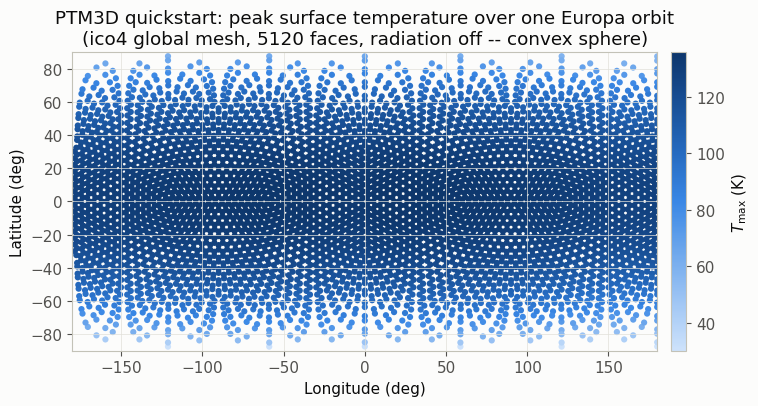

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sc = ax.scatter(lon, lat, c=stats["temperature_max"], cmap=seq_blue,
                 s=20, linewidths=0)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xlabel("Longitude (deg)")
ax.set_ylabel("Latitude (deg)")
ax.set_title(f"PTM3D quickstart: peak surface temperature over one Europa orbit\n"
             f"(ico4 global mesh, {len(lat)} faces, radiation off -- convex sphere)")
ax.grid(True, linewidth=0.5)
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label(r"$T_\mathrm{max}$ (K)")
plt.tight_layout()
plt.show()


### Locating the eclipse

An eclipse is a **global** event — the whole day side loses the Sun at once,
not a per-face terminator sweep — so the clearest signature is the **total
direct solar flux summed over all faces**. The cell below computes that sum
per output step and reports every step where it is exactly zero.


In [11]:
n_steps = cfg["simulation"]["timesteps"] if cfg else 192
direct_dir = OUT_DIR / "direct_solar"

global_direct = np.array([load_bin(direct_dir / f"direct_solar_{t:04d}.bin").sum()
                           for t in range(n_steps)])
n_lit = np.array([int(np.sum(load_bin(direct_dir / f"direct_solar_{t:04d}.bin") > 0.1))
                   for t in range(n_steps)])

eclipse_steps = np.where(global_direct < 1e-6)[0]
print(f"Global direct-solar flux: {global_direct.min():.1f} - {global_direct.max():.1f} W/m^2 "
      f"(summed over all {len(lat)} faces per step)")
print(f"n_lit faces per step (non-eclipse, non-fully-dark steps): "
      f"{n_lit[n_lit>0].min()} - {n_lit.max()} of {len(lat)}")
print(f"\nSteps with EXACTLY zero global direct flux (full-body eclipse): {list(eclipse_steps)}")
if len(eclipse_steps) == 0:
    raise RuntimeError(
        "No eclipse found in this run's output window -- the config's start_time "
        "no longer captures one (SPICE ephemeris/geometry may have changed, or "
        "the window/cadence shifted). The eclipse analysis below depends on "
        "this window."
    )

lines = [ln.split() for ln in (OUT_DIR / "time_steps.txt").read_text().splitlines()
         if ln.strip() and not ln.startswith("#")]
utc = [row[1] for row in lines]
print(f"\nEclipse window (UTC labels): {utc[eclipse_steps[0]]} -> {utc[eclipse_steps[-1]]}")
print(f"({len(eclipse_steps)} fully-dark output steps out of {n_steps}; true eclipse "
      "duration is somewhat longer than this, since the steps immediately before/after "
      "are already partway into ingress/egress)")


Global direct-solar flux: 0.0 - 67600.8 W/m^2 (summed over all 5120 faces per step)
n_lit faces per step (non-eclipse, non-fully-dark steps): 2546 - 2559 of 5120

Steps with EXACTLY zero global direct flux (full-body eclipse): [40, 41, 42, 43, 44, 45]

Eclipse window (UTC labels): 2025-01-01T18:08:07.923 -> 2025-01-01T20:21:22.363
(6 fully-dark output steps out of 192; true eclipse duration is somewhat longer than this, since the steps immediately before/after are already partway into ingress/egress)


### The eclipse's thermal fingerprint on one face

Pick the face with the highest direct-solar flux in the output step
*immediately before* the eclipse (a face near local noon at that moment —
the most dramatic case) and plot its full diurnal temperature curve, with
the eclipse window shaded.

Selected face: index 5058, lat=2.36 deg, lon=6.39 deg (direct solar 52.6 W/m^2 at step 39, just before ingress)


192 output steps spanning 84.8 h (3.53 d); cadence 0.44 h/step

Pre-eclipse local peak:  step 39  T=135.0 K  (flux=52.6 W/m^2)
Eclipse-window minimum:  step 45  T=112.0 K  (flux=0.0 W/m^2)
Post-eclipse local peak: step 54  T=131.4 K  (flux=46.1 W/m^2)

Cooling during eclipse: 23.0 K in 2.7 h


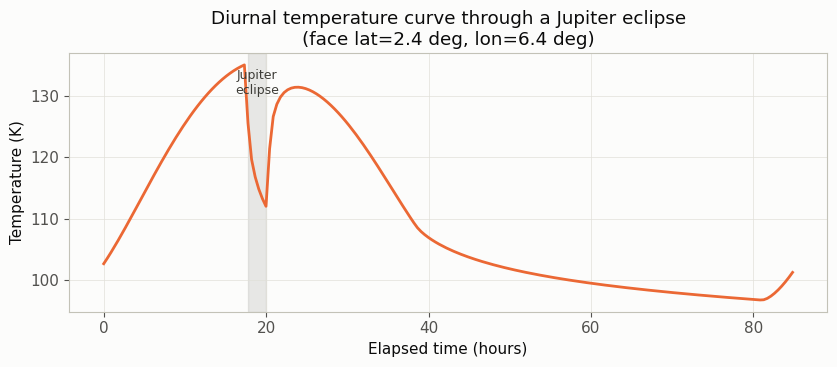

In [12]:
pre_eclipse_step = eclipse_steps[0] - 1
ds_pre = load_bin(direct_dir / f"direct_solar_{pre_eclipse_step:04d}.bin")
face = int(np.argmax(ds_pre))
print(f"Selected face: index {face}, lat={lat[face]:.2f} deg, lon={lon[face]:.2f} deg "
      f"(direct solar {ds_pre[face]:.1f} W/m^2 at step {pre_eclipse_step}, just before ingress)")

temp_dir = OUT_DIR / "temperature"
curve = np.array([load_bin(temp_dir / f"temperature_{t:04d}.bin")[face]
                   for t in range(n_steps)])
flux_curve = np.array([load_bin(direct_dir / f"direct_solar_{t:04d}.bin")[face]
                        for t in range(n_steps)])

t_et = np.array([float(row[0]) for row in lines])
t_hr = (t_et - t_et[0]) / 3600.0
cadence_hr = float(np.median(np.diff(t_hr)))
print(f"{len(t_hr)} output steps spanning {t_hr[-1]:.1f} h ({t_hr[-1]/24:.2f} d); "
      f"cadence {cadence_hr:.2f} h/step")

t_peak_before = curve[:eclipse_steps[0]].argmax()
t_trough = eclipse_steps[0] + curve[eclipse_steps[0]:eclipse_steps[-1]+1].argmin()
t_peak_after = eclipse_steps[-1] + 1 + curve[eclipse_steps[-1]+1:].argmax()
print(f"\nPre-eclipse local peak:  step {t_peak_before}  T={curve[t_peak_before]:.1f} K  "
      f"(flux={flux_curve[t_peak_before]:.1f} W/m^2)")
print(f"Eclipse-window minimum:  step {t_trough}  T={curve[t_trough]:.1f} K  "
      f"(flux={flux_curve[t_trough]:.1f} W/m^2)")
print(f"Post-eclipse local peak: step {t_peak_after}  T={curve[t_peak_after]:.1f} K  "
      f"(flux={flux_curve[t_peak_after]:.1f} W/m^2)")
print(f"\nCooling during eclipse: {curve[t_peak_before]-curve[t_trough]:.1f} K "
      f"in {(t_hr[t_trough]-t_hr[t_peak_before]):.1f} h")

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(t_hr, curve, color=ACCENT_ORANGE, linewidth=2)
ax.axvspan(t_hr[eclipse_steps[0]], t_hr[eclipse_steps[-1]], color=NEUTRAL_BAND, alpha=0.18,
           zorder=0)
ymin, ymax = ax.get_ylim()
ax.text((t_hr[eclipse_steps[0]] + t_hr[eclipse_steps[-1]]) / 2, ymax - 0.06 * (ymax - ymin),
        "Jupiter\neclipse", ha="center", va="top", fontsize=9, color="#3d3c37")
ax.set_xlabel("Elapsed time (hours)")
ax.set_ylabel("Temperature (K)")
ax.set_title(f"Diurnal temperature curve through a Jupiter eclipse\n"
             f"(face lat={lat[face]:.1f} deg, lon={lon[face]:.1f} deg)")
ax.grid(True, linewidth=0.5)
plt.tight_layout()
plt.show()


## Day/night contrast — and the cross-reference to the Moon

The plot below is Europa's version of the Moon notebook's "day/night
contrast vs. latitude" plot ($T_\mathrm{max}-T_\mathrm{min}$ per face). The
interpretation section quantifies the cross-body comparison explicitly.

day/night contrast (Tmax-Tmin): min=0.0  max=47.0  median=36.0  mean=33.4 K  (n_distinct@0.1K=425, range=47.0 K)
correlation with |latitude|: r = -0.91


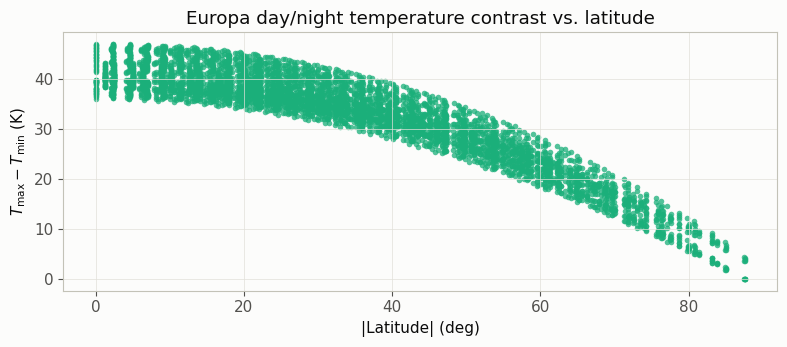


Median-face day/night swing:
  Moon   (cited, not re-run here): 369.8 - 92.6 K = 277.2 K swing, Tmin/Tmax = 0.25
  Europa (this run):               124.9 - 87.3 K = 37.5 K swing, Tmin/Tmax = 0.70


In [13]:
contrast = stats["temperature_max"] - stats["temperature_min"]
n_distinct_contrast = len(np.unique(np.round(contrast, 1)))
corr = float(np.corrcoef(np.abs(lat), contrast)[0, 1])
print(f"day/night contrast (Tmax-Tmin): min={contrast.min():.1f}  "
      f"max={contrast.max():.1f}  median={np.median(contrast):.1f}  mean={contrast.mean():.1f} K  "
      f"(n_distinct@0.1K={n_distinct_contrast}, range={contrast.max()-contrast.min():.1f} K)")
print(f"correlation with |latitude|: r = {corr:.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(np.abs(lat), contrast, color=ACCENT_AQUA, s=16, alpha=0.75, linewidths=0)
ax.set_xlabel("|Latitude| (deg)")
ax.set_ylabel(r"$T_\mathrm{max} - T_\mathrm{min}$ (K)")
ax.set_title("Europa day/night temperature contrast vs. latitude")
ax.grid(True, linewidth=0.5)
plt.tight_layout()
plt.show()

moon_tmax_med, moon_tmin_med = 369.8, 92.6  # docs/tutorials/02_lunar_diurnal_icosphere.md, v1.0.3, 2026-08-05
europa_tmax_med = float(np.median(stats["temperature_max"]))
europa_tmin_med = float(np.median(stats["temperature_min"]))
print(f"\nMedian-face day/night swing:")
print(f"  Moon   (cited, not re-run here): {moon_tmax_med:.1f} - {moon_tmin_med:.1f} K "
      f"= {moon_tmax_med-moon_tmin_med:.1f} K swing, Tmin/Tmax = {moon_tmin_med/moon_tmax_med:.2f}")
print(f"  Europa (this run):               {europa_tmax_med:.1f} - {europa_tmin_med:.1f} K "
      f"= {europa_tmax_med-europa_tmin_med:.1f} K swing, Tmin/Tmax = {europa_tmin_med/europa_tmax_med:.2f}")


## 5. Interpretation

**The eclipse's thermal fingerprint.** The shaded band marks ~2.7 h where
direct solar flux is *exactly* zero, body-wide: Europa is inside Jupiter's
shadow, so the whole day side loses the Sun at once. The selected face's
temperature does not follow the flux to zero — printed above, it cools by
roughly 20 K over those ~2.7 h, limited by the same thin conductive skin
layer that governs the normal diurnal cycle (below). When sunlight returns,
the temperature only partially recovers: the post-eclipse local peak lands
below the pre-eclipse peak, because the eclipse cut off part of the rise
toward local noon. The flux discontinuity (full daytime flux to zero in one
SPICE-geometry transition) is also why `docs/thermal-model.md` describes an
"event-aware" adaptive timestep controller for resolving eclipses.

**Ice thermal inertia.** Europa's default porous-ice regolith
($k_s=0.0096$ W/m/K, $\rho_s=500$ kg/m³, $c_p(100\,\mathrm{K})\approx750$
J/kg/K) gives a diurnal thermal skin depth
$\delta=\sqrt{\kappa P/\pi}\approx5$ cm for the 3.55-day period. A thin skin
depth means the surface layer's heat content is small: it responds quickly
(the ~20 K eclipse cooling in under 3 hours), but it also stores
comparatively little heat to buffer the night.

**Why Europa's night stays warm relative to its day.** The printed comparison
above quantifies it: the Moon's median-face day/night ratio
($T_\mathrm{min}/T_\mathrm{max}$) is around 0.25; Europa's is around 0.7.
The main reason is not the material — the thermal inertias are broadly
comparable — but the night length: **Europa's night is only 1.775 Earth days
long**, against the Moon's ~14.75-day lunar night, so there is roughly 8x
less time for stored daytime heat to radiate away before the next sunrise.
The run itself shows the size of the effect: the handful of
**permanently-unlit near-polar faces** (printed in section 3) sit at the
zero-insolation geothermal floor $T=(Q_b/\epsilon\sigma)^{1/4}\approx28$ K,
while every *normally-illuminated* face's nighttime floor is 87-97 K — i.e.
60-70 K of retained daytime heat that the short Europa night has not had
time to shed. It is the same mechanism as the Moon's nighttime plateau,
proportionally much larger here because of the orbital period, not the
material properties.

**Never-illuminated faces as a built-in floor check.** A face that receives
zero flux, ever, should sit at the internal-heat-flux-only equilibrium
$T=(Q_b/\epsilon\sigma)^{1/4}$. With this config's $Q_b=0.03$ W/m² and
$\epsilon=0.9$, that predicts 27.7 K — matching the ~30 K observed for those
faces to within the coarse-mesh grazing-incidence residual.


## 6. Exercises

1. **Change the albedo.** `thermophysical.albedo_override` (a top-level key
   next to `use_default_albedo`) overrides the built-in Bond albedo 0.5 with
   any value $\ge0$ — e.g. `albedo_override: 0.3` for a darker,
   non-ice-dominated patch (real spatial variation is what
   `configs/europa_ico6_albedo-map.yaml`'s FITS map encodes; this override
   is a uniform stand-in). Lower albedo absorbs more flux — re-run and
   compare both the peak and whether the night-side floor moves as much as
   the peak does (thermal-inertia damping should make the night respond
   less).

2. **Eclipse on/off comparison.** The eclipse is not a config flag — it is
   real SPICE geometry, and every full-orbit window contains exactly one.
   For an eclipse-free comparison window, shorten and shift the run: try
   `start_time: '2025-01-02T00:00:00'` with `duration_days: 1.5` (adjust
   `timesteps` down proportionally, e.g. to `~81`, to keep the same
   ~26.6 min cadence) — this window sits entirely between the eclipse this
   notebook found and the next one (one full orbit, ~85.2 h, later). Apply
   the same face-selection logic from section 4 and compare the
   *uninterrupted* peak temperature to this run's post-eclipse peak.

3. **`include_primary_reflection: false`.** Set it false and re-run. In the
   printed final "Results" block, `Primary reflected` flux drops to ~0 while
   `Primary IR` is essentially unchanged — the asymmetric gating described
   in section 1.

4. **Resolution.** Bump `mesh.resolution: 4` to `5` (5120 → 20,480 faces) or
   `6` (81,920 faces, the resolution the `configs/europa_ico6_*.yaml`
   production configs use) for a sharper map. Check
   `scripts/ptm_mem_estimate.py --faces 20480 --steps 192` before running —
   still laptop-sized, but no longer instant.


## Version

The binary and commit that produced the numbers in this notebook.


In [14]:
import hashlib
import subprocess as sp

md5 = hashlib.md5(BINARY.read_bytes()).hexdigest()
print("Binary:", BINARY)
print("MD5:   ", md5)

try:
    commit = sp.run(
        ["/Library/Developer/CommandLineTools/usr/bin/git", "rev-parse", "HEAD"],
        cwd=str(REPO_ROOT), capture_output=True, text=True, check=True,
    ).stdout.strip()
    branch = sp.run(
        ["/Library/Developer/CommandLineTools/usr/bin/git", "rev-parse", "--abbrev-ref", "HEAD"],
        cwd=str(REPO_ROOT), capture_output=True, text=True, check=True,
    ).stdout.strip()
    print("Commit:", commit, f"({branch})")
except Exception as exc:  # pragma: no cover -- version info is best-effort
    print("(git information unavailable in this environment:", exc, ")")

print(f"\nWall time of the run in section 2: {wall_time_s:.1f} s")


Binary: /Users/paha3326/Projects/ptm-tutedit/build/bin/ptm_thermal_sim
MD5:    95bea53ffdac4e85671cc02fcfff1bba


Commit: 0b97202af7261426e8d5906708abfe13c312a4fd (docs/tutorials-editorial)

Wall time of the run in section 2: 5.0 s
